In [36]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import src.configs.config as cfg; import src.spectrum as spectrum; import src.signals as signals; import src.array as array
import src.configs.comon as comon
import os
import time
from src.plotting import plot_variance_vs_param, plot_mean_vs_param
from src.functions import (
                       tau_array,
                       covariation_matrix,
                       channel_matrix,
                       get_sin_signal, 
                       complex_stiring_matrix,
                       calculate_full_bartlett_values, 
                       )
from src.functions import (
                       calculate_bartlett_values,
                       calculate_stiring_matrix, 
                       get_est_phi)
from src.experiments import (stat_vs_params, calculate_variance)
config_parametrs = cfg.init_rng()
path = "attachment/images/notebook"
os.makedirs(path,exist_ok=True)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [37]:
from scipy.signal import hilbert
sin_signal = signals.get_sin_signal(config_parametrs)
# Преобразование гильберта возращает уже весь аналитический сигнал (real + imag)
# hilbert(s(t)) = s(t) + h(s(t)) 

In [38]:
tau_array = array.tau_array(config_parametrs)
channel_real_matrix = array.channel_matrix(config_parametrs, tau_array, get_sin_signal)
channel_complex_matrix = hilbert(channel_real_matrix.real,axis = 1)

w_real = covariation_matrix(channel_real_matrix, config_parametrs["N"])
w_complex = covariation_matrix(channel_complex_matrix, config_parametrs["N"])
dir_complex_matrix = array.complex_stiring_matrix(config_parametrs)



bartlett_real = calculate_full_bartlett_values(w_real, dir_complex_matrix)
bartlett_complex = calculate_full_bartlett_values(w_complex, dir_complex_matrix)

print(np.argmax(np.real(bartlett_real)), np.argmax(np.real(bartlett_complex)))
print(np.array_equal(bartlett_real, bartlett_complex))

1050 1051
False


In [39]:


complex_e_max = max(bartlett_complex)
complex_est_phi = get_est_phi(config_parametrs["phi_vector"], bartlett_complex) 


real_e_max = max(bartlett_real)
real_est_phi = get_est_phi(config_parametrs["phi_vector"], bartlett_real) 


print((complex_est_phi*180) / np.pi)
print((real_est_phi*180) / np.pi)


60.21964029922012
60.16234282985834


d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


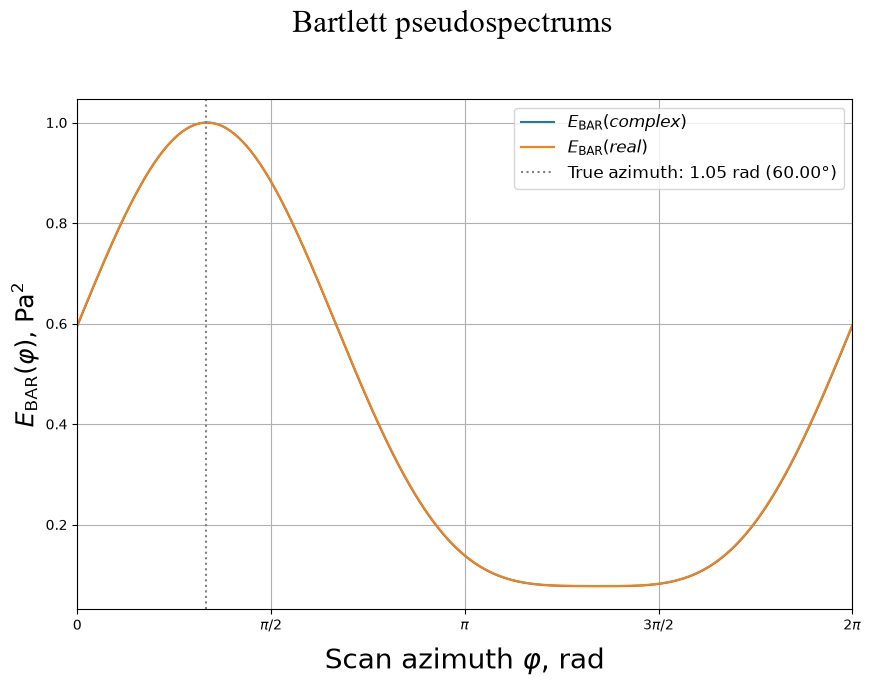

In [40]:
title_main = "Bartlett pseudospectrums"


fig, ax = plt.subplots(figsize = (10,10))
fig.subplots_adjust(top=0.85, bottom=0.34)

# Функция Бартлетта и отметки углов.
ax.plot(
    config_parametrs["phi_vector"], bartlett_complex / complex_e_max,
    label=r"$E_{\mathrm{BAR}} (complex)$"
)
ax.plot(
    config_parametrs["phi_vector"], bartlett_real / real_e_max,
    label=r"$E_{\mathrm{BAR}} (real)$",
)
ax.axvline(
    config_parametrs["target_phi"], color="gray", linestyle=":",
    label=f"True azimuth: {config_parametrs["target_phi"]:.2f} rad ({np.degrees(config_parametrs["target_phi"]):.2f}°)"
)
# Названия осей и заголовок
fig.suptitle(
    title_main,
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.set_xlabel(r"Scan azimuth $\varphi$, rad", labelpad=10, fontsize=20)
ax.set_ylabel(r"$E_{\mathrm{BAR}}(\varphi)$, Pa$^2$", fontsize=18)

ax.set_xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
)

ax.set_xlim(0, 2 * np.pi)
ax.legend(loc="upper right", fontsize=12)
ax.grid(True)



In [41]:
config_random = dict( # noqa: C408
                    is_CRN = True, 
                    is_random_start = False)

config_bartlett_for_real_signal = dict(  # noqa: C408
                            energy_func = calculate_full_bartlett_values,
                            signal_func = get_sin_signal,
                            stiring_func = array.complex_stiring_matrix,
                            **config_random)
config_bartlett_for_complex_signal  = dict(  # noqa: C408
                            energy_func = calculate_full_bartlett_values,
                            signal_func = get_sin_signal,
                            stiring_func = array.complex_stiring_matrix,
                            is_hilbert = True,
                            **config_random)

In [32]:
config_parametrs1 = cfg.restart_rng(config_parametrs)
config_parametrs2 = config_parametrs1
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "target_phi",
    parametr_values = cfg.PHI_VALUES) 
var_bartlett_vs_phis = stat_vs_params(config_params=config_parametrs1,
                                     stat_func = calculate_variance,
                                   **config_bartlett_for_real_signal,
                                   **parametr_config, )

var_bartlett_vs_phis_complex = stat_vs_params(config_params = config_parametrs2,
                                             stat_func = calculate_variance,
                                             **config_bartlett_for_complex_signal,
                                             **parametr_config)
var_delta_abs = np.abs(np.array(var_bartlett_vs_phis) - np.array(var_bartlett_vs_phis_complex))
end_time = time.perf_counter()


config_parametrs1 = cfg.restart_rng(config_parametrs)
config_parametrs2 = config_parametrs1



mean_bartlett_vs_phis = stat_vs_params(config_params=config_parametrs1,
                                     stat_func = np.mean,
                                   **config_bartlett_for_real_signal,
                                   **parametr_config, )

mean_bartlett_vs_phis_complex = stat_vs_params(config_params = config_parametrs2,
                                             stat_func = np.mean,
                                             **config_bartlett_for_complex_signal,
                                             **parametr_config)
mean_delta_abs = np.abs(np.array(mean_bartlett_vs_phis) - np.array(mean_bartlett_vs_phis_complex))
end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='Source azimuth $\\varphi_0$, deg', ylabel='$\\mathbb{E}[\\varepsilon]$, deg'>)

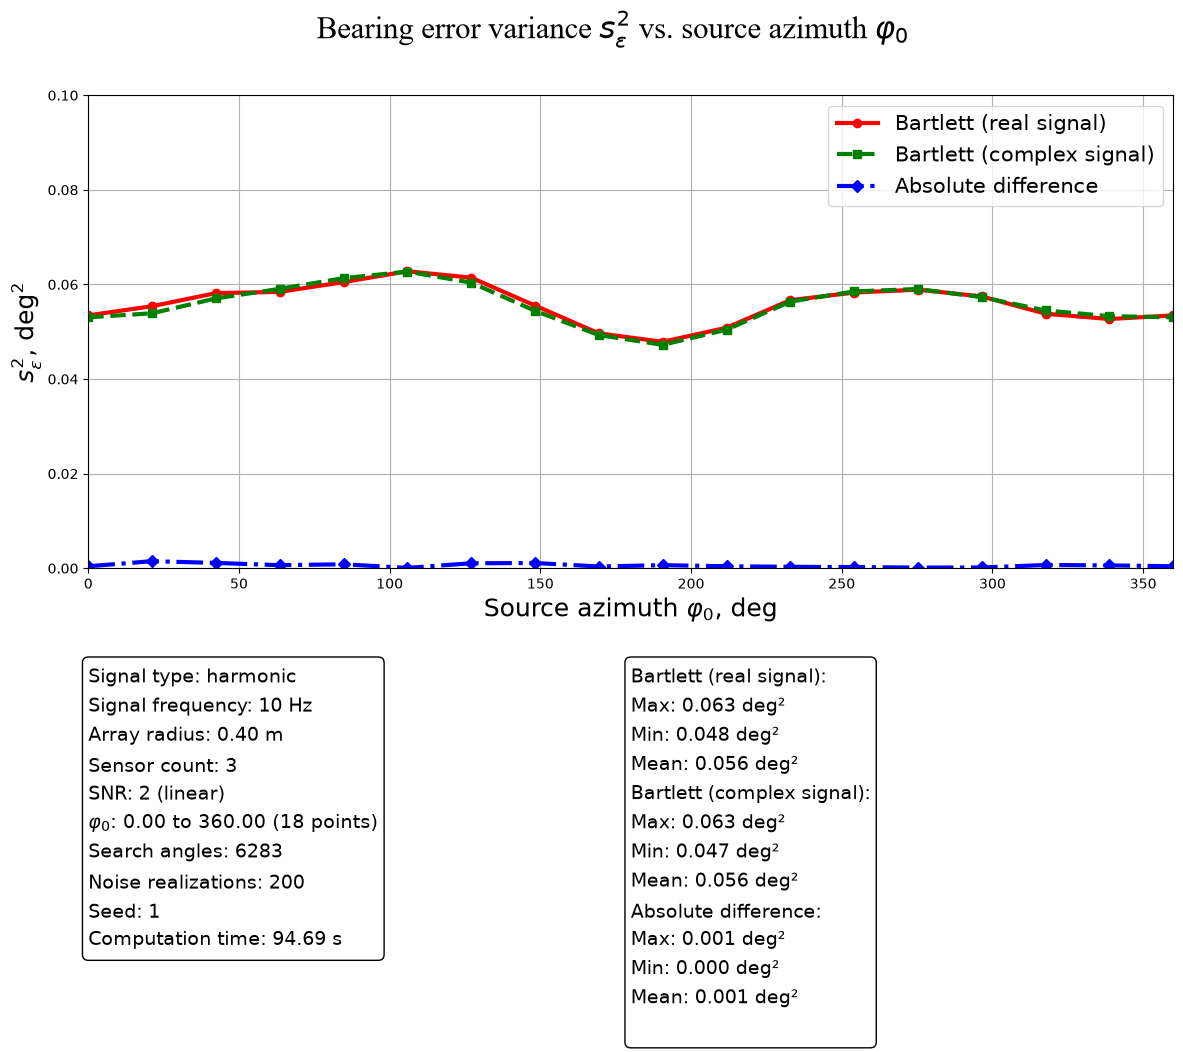

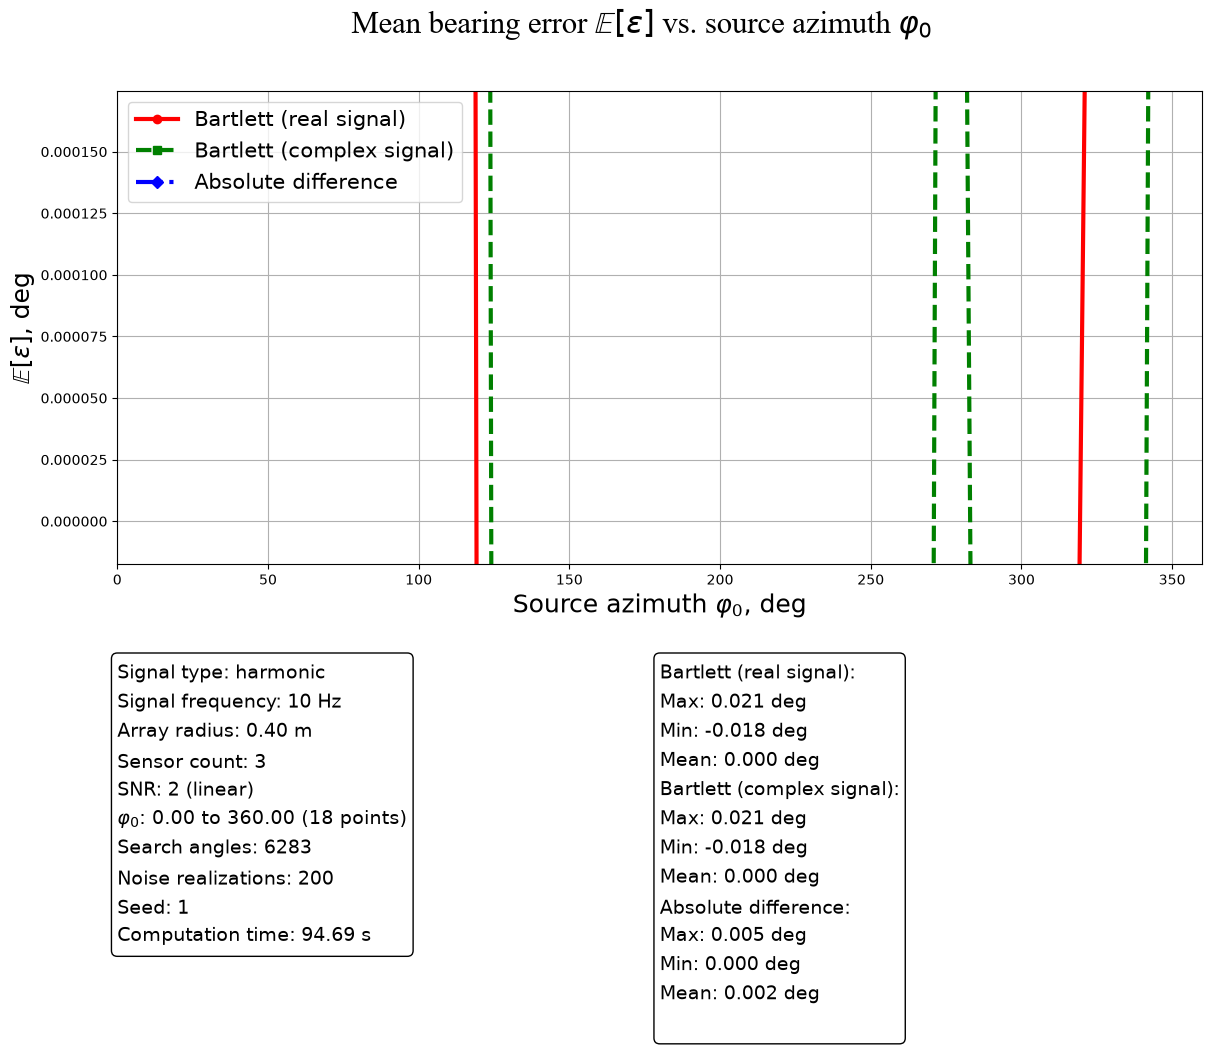

In [33]:
plot_variance_vs_param(dict_values = {"Bartlett (real signal)": var_bartlett_vs_phis,
                                      "Bartlett (complex signal)": var_bartlett_vs_phis_complex,
                                      "Absolute difference": var_delta_abs},
                       config_params = config_parametrs.copy(),
                       delta_time = delta_time,
                       ylim = (0.00*comon.CONST_RADIAN, 0.1*comon.CONST_RADIAN),
                       xlim = (0,360),
                       type_signal = "garmonic",
                       **parametr_config)
plot_mean_vs_param(dict_values = {"Bartlett (real signal)": mean_bartlett_vs_phis,
                                      "Bartlett (complex signal)": mean_bartlett_vs_phis_complex,
                                      "Absolute difference": mean_delta_abs},
                       config_params = config_parametrs.copy(),
                       delta_time = delta_time,
                       ylim = (-.001*comon.CONST_RADIAN, 0.01*comon.CONST_RADIAN),
                       xlim = (0,360),
                       type_signal = "garmonic",
                       **parametr_config)

In [34]:
config_parametrs1 = cfg.restart_rng(config_parametrs)
config_parametrs2 = config_parametrs1
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "snr",
    parametr_values = cfg.SNR_VALUES) 
var_bartlett_vs_snr = stat_vs_params(config_params=config_parametrs1,
                                     stat_func = calculate_variance,
                                   **config_bartlett_for_real_signal,
                                   **parametr_config, )

var_bartlett_vs_snr_complex = stat_vs_params(config_params = config_parametrs2,
                                             stat_func = calculate_variance,
                                             **config_bartlett_for_complex_signal,
                                             **parametr_config)
var_delta_abs = np.abs(np.array(var_bartlett_vs_snr) - np.array(var_bartlett_vs_snr_complex))
end_time = time.perf_counter()
delta_time = end_time - start_time

(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='SNR (linear)', ylabel='$s_{\\varepsilon}^{2}$, deg$^2$'>)

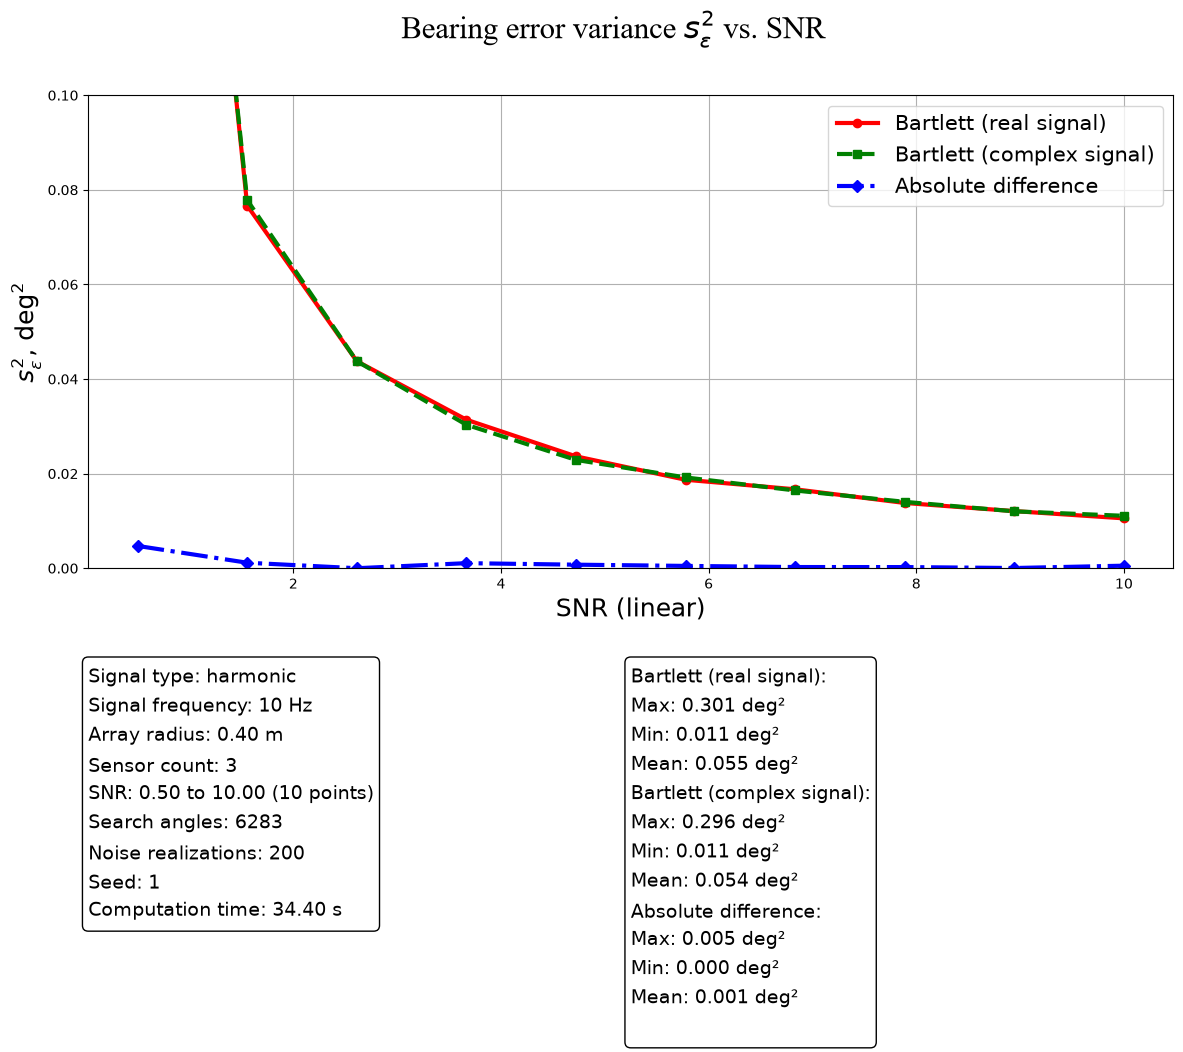

In [35]:
plot_variance_vs_param(dict_values = {"Bartlett (real signal)": var_bartlett_vs_snr,
                                      "Bartlett (complex signal)": var_bartlett_vs_snr_complex,
                                      "Absolute difference": var_delta_abs},
                       config_params = config_parametrs.copy(),
                       delta_time = delta_time,
                       ylim = (0.00*comon.CONST_RADIAN, 0.1*comon.CONST_RADIAN),
                       #xlim = (0,360),
                       type_signal = "garmonic",
                       **parametr_config)

## Зависимость от частоты гармонического сигнала

Для каждой частоты пересчитываются гармонический сигнал и комплексный стиринг-вектор. Для вещественной и аналитической ветвей используются одинаковые начальные состояния генератора и одна формула Бартлетта.

In [ ]:
config_parametrs1 = cfg.restart_rng(config_parametrs)
config_parametrs2 = cfg.restart_rng(config_parametrs)
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "f0",
    parametr_values = cfg.FREQ_VALUES)


def calculate_variance_and_mean(list_errors):
    return calculate_variance(list_errors), np.mean(list_errors)


var_bartlett_vs_f, mean_bartlett_vs_f = np.asarray(
    stat_vs_params(config_params=config_parametrs1,
                   stat_func=calculate_variance_and_mean,
                   **config_bartlett_for_real_signal,
                   **parametr_config)).T
var_bartlett_vs_f_complex, mean_bartlett_vs_f_complex = np.asarray(
    stat_vs_params(config_params=config_parametrs2,
                   stat_func=calculate_variance_and_mean,
                   **config_bartlett_for_complex_signal,
                   **parametr_config)).T

var_delta_abs = np.abs(var_bartlett_vs_f - var_bartlett_vs_f_complex)
mean_delta_abs = np.abs(mean_bartlett_vs_f - mean_bartlett_vs_f_complex)
delta_time = time.perf_counter() - start_time

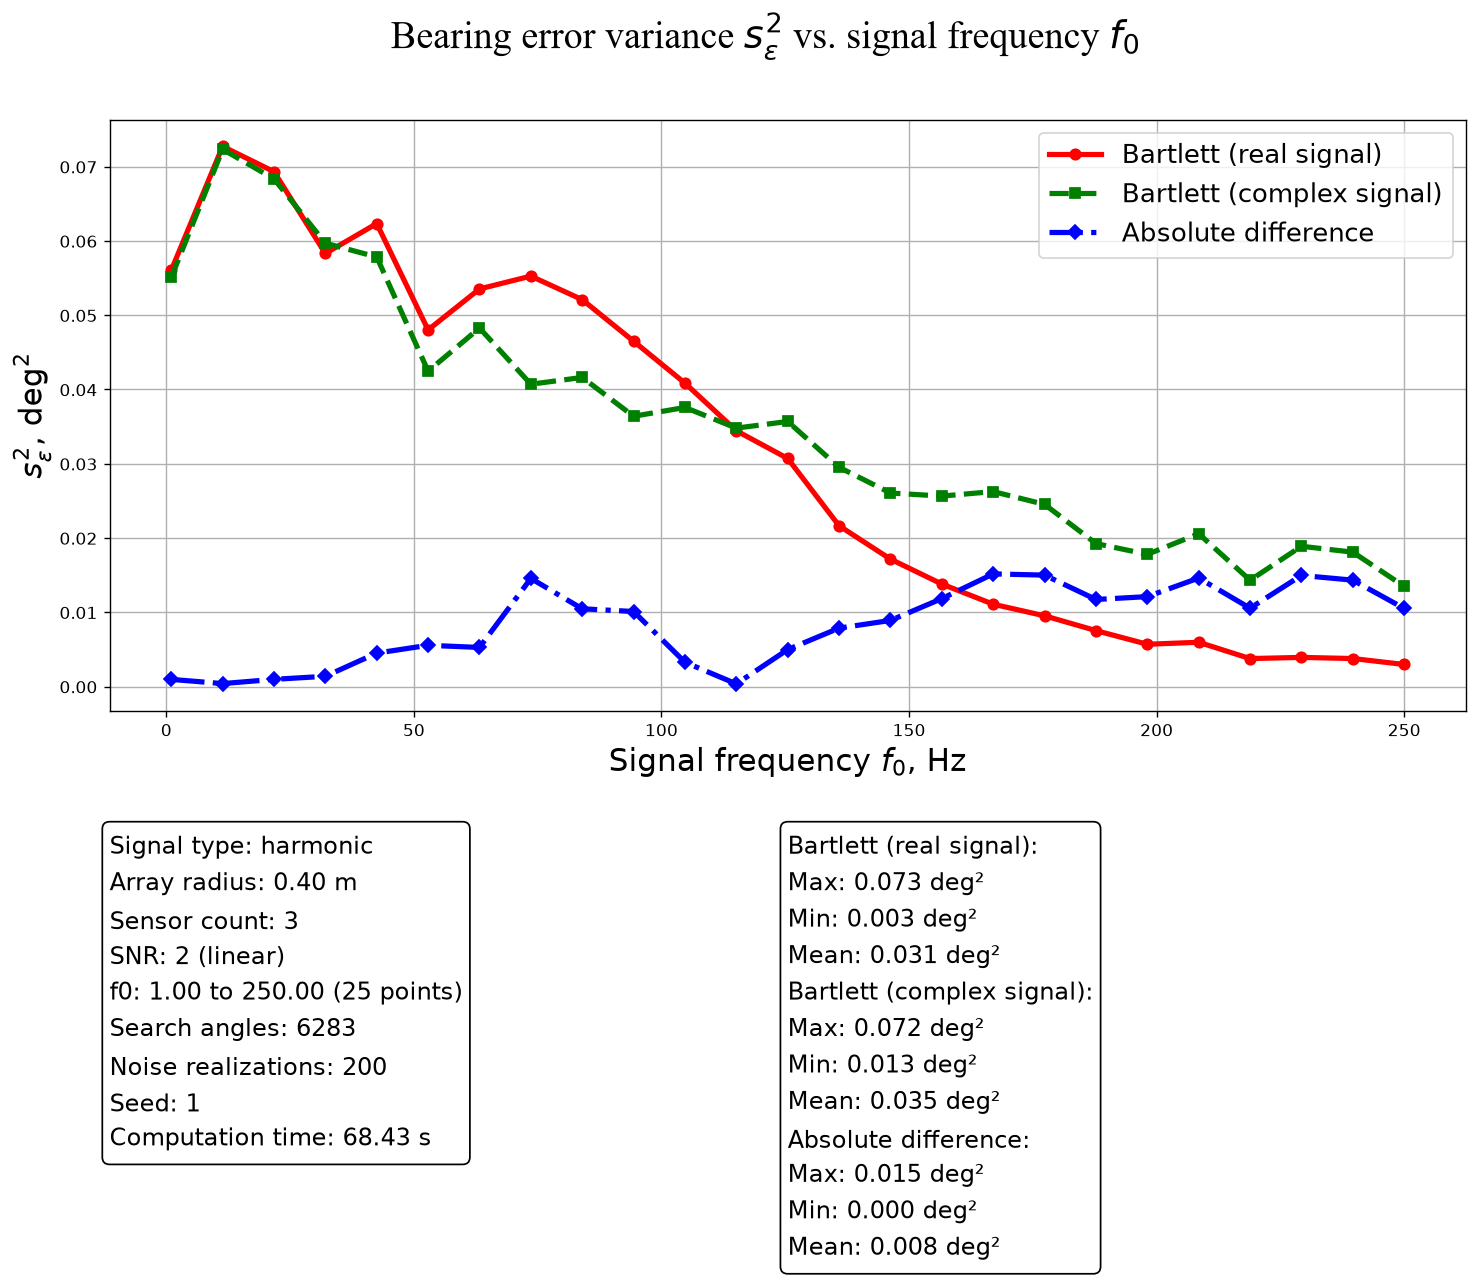

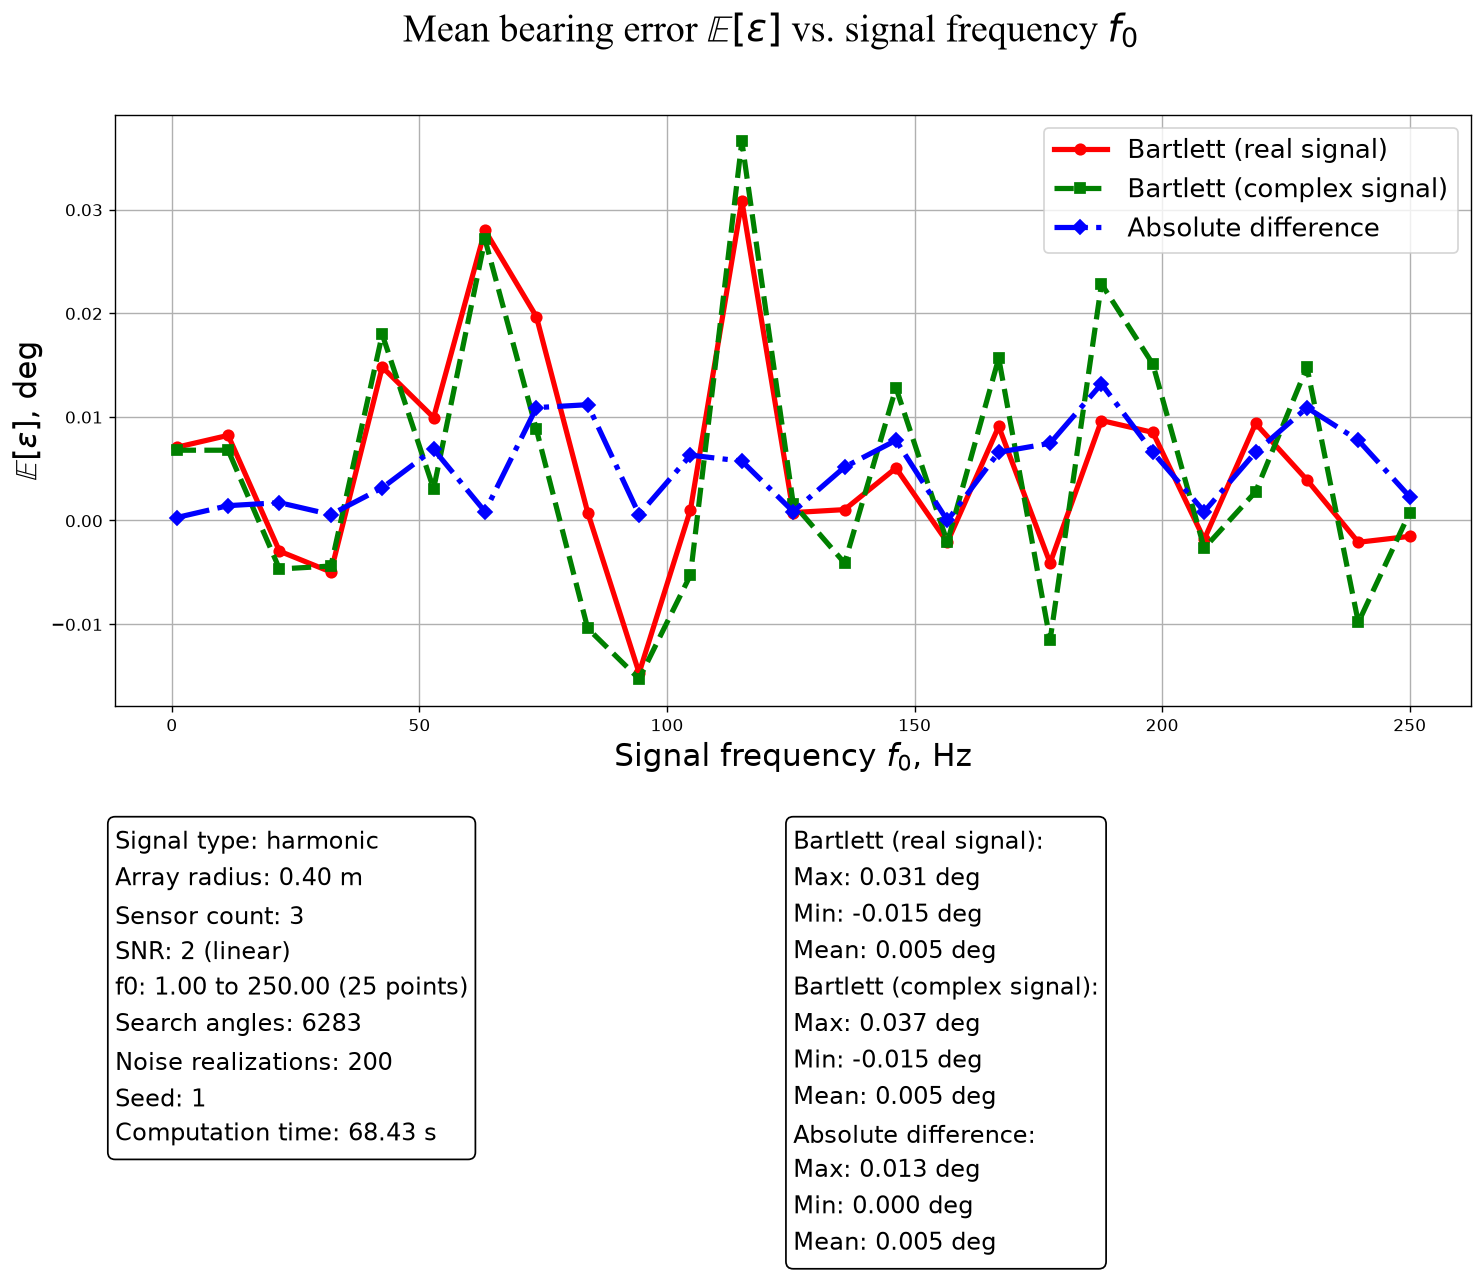

In [ ]:
fig_var, ax_var = plot_variance_vs_param(
    dict_values={"Bartlett (real signal)": var_bartlett_vs_f,
                 "Bartlett (complex signal)": var_bartlett_vs_f_complex,
                 "Absolute difference": var_delta_abs},
    config_params=config_parametrs.copy(),
    delta_time=delta_time,
    type_signal="garmonic",
    **parametr_config)

fig_mean, ax_mean = plot_mean_vs_param(
    dict_values={"Bartlett (real signal)": mean_bartlett_vs_f,
                 "Bartlett (complex signal)": mean_bartlett_vs_f_complex,
                 "Absolute difference": mean_delta_abs},
    config_params=config_parametrs.copy(),
    delta_time=delta_time,
    type_signal="garmonic",
    **parametr_config)

# На графике меняется частота, поэтому убираем фиксированное значение из подписи.
for ax in (ax_var, ax_mean):
    for text in ax.texts:
        text.set_text("\n".join(line for line in text.get_text().splitlines()
                                if not line.startswith("Signal frequency:")))
plt.show()

## Вывод: 
Реализовано сравнение точности пелингования азимута по методу Бартлетта с использованием вещественной и комлпексной ковариационными матрицами. Для точности сравнения использован метод Comon Random Numbers:
Были построены зависимости дисперсии ошибки от истинного направления источника при SNR = 2 и 0.2.

Для наименьшего значения SNR среднее значение диссперсии отличалось в среднем на 0.012 град ^2, что составлят отклонение на 1.25 % 

Можно предположить, что природа погрешности возможна из-за искажения после преобразования Гильберта, но это влиянеие нужно проверить. 

По проведенным эксперементам можно сделать вывод, что использование комплексной ковариационной матрицы для гармонического сигнла в точной моделе с текущими параметрами конфигурации излише.

При изменении частоты результат для 10 Гц на весь диапазон не переносится. При SNR = 2 на проверенных частотах до 42,5 Гц разность дисперсий по модулю не превышала 0,00451 град². При 73,625 Гц с преобразованием Гильберта дисперсия уменьшилась с 0,05527 до 0,04071 град², а при 167 Гц увеличилась с 0,01108 до 0,02625 град².